# 03 — Baseline Model: Linear Regression

**Project:** California Property Close Price Prediction (IDX Exchange Data Science Internship)
**Week 4 deliverable:** this notebook.

**Week 4 tasks (game plan):** train a Linear Regression as the first model, evaluate it on the test set, and record the baseline results that every later model must beat.

**Setup carried over from Week 3 (unchanged):**
- Target: `log(ClosePrice)`. Predictions are converted back to dollars with `exp()`, and every metric is computed in dollars.
- Inputs: the same 24 features, all available for any address at prediction time. `ListPrice`, `OriginalListPrice`, `DaysOnMarket`, `PurchaseContractDate`, `ListingContractDate` and anything derived from them are never inputs; price per sq ft enters only through comps (nearby *earlier* sales). `pp.assert_no_leakage()` runs before every fit.
- Split: train = January 2025 – March 2026 (X = 15 months, chosen in Week 3 on validation months only), test = April 2026. Outlier thresholds were learned on train only.
- Model: one scikit-learn `Pipeline` = Week 3 preprocessor (imputation, one-hot, cross-fitted target encoding, scaling; fit on train only) + `LinearRegression`.

**Evaluation (AVM best-practices doc, sections 01, 08, 09):** MdAPE is the headline metric, reported with R², MAPE, MAE and RMSE. Error is broken out by price band and county, and the same pipeline is re-run at three earlier cutoffs (rolling-origin backtest) to check that the April score is not a lucky month. The test month is scored once, after the validation checks.

Shared code: `py/preprocessing.py` (Week 3) and `py/modeling.py` (new this week: pipeline, metrics, error breakdowns, backtest), so Week 5 models are evaluated with exactly the same code.

## 1. Setup

In [1]:
import sys, json, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import joblib
import sklearn
from sklearn.linear_model import LinearRegression

ROOT = next(p for p in [Path("."), Path("..")] if (p / "processed").exists()).resolve()
sys.path.insert(0, str(ROOT / "py"))
import preprocessing as pp
import modeling as mdl

PROC, FIG_DIR = ROOT / "processed", ROOT / "figures" / "03_baseline_model"
RES_DIR, MODEL_DIR = ROOT / "results", ROOT / "models"
for d in (FIG_DIR, RES_DIR, MODEL_DIR): d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#d0cfca", "grid.color": "#ecebe7",
                                     "axes.titleweight": "bold", "figure.dpi": 110})
def save(fig, name): fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=130)
def show_metrics(df):
    fmt = {"n": "{:,.0f}", "n_train": "{:,.0f}", "MdAPE": "{:.2f}%", "R2": "{:.4f}", "R2_log": "{:.4f}",
           "MAPE": "{:.2f}%", "MAE": "${:,.0f}", "RMSE": "${:,.0f}", "MedAE": "${:,.0f}",
           "within_5pct": "{:.1f}%", "within_10pct": "{:.1f}%", "within_20pct": "{:.1f}%",
           "median_bias_pct": "{:+.2f}%"}
    return fmt_table(df, fmt)
def fmt_table(df, spec):
    # formatted copy for display (plain DataFrame, no jinja2 needed); saved CSVs keep raw numbers
    out = df.copy()
    for c, f in spec.items():
        if c in out.columns: out[c] = out[c].map(lambda v, f=f: f.format(v) if pd.notna(v) else "")
    return out
GROUP_FMT = {"n": "{:,.0f}", "median_price": "${:,.0f}", "MdAPE": "{:.2f}%", "MAPE": "{:.2f}%",
             "MAE": "${:,.0f}", "within_10pct": "{:.1f}%", "median_bias": "{:+.2f}%"}

np.random.seed(pp.SEED)
pp.assert_no_leakage()
cfg = json.loads((PROC / "preprocessing_config.json").read_text())
X_MONTHS, TEST_MONTH = cfg["train_window_months"], cfg["test_month"]
print("Project folder:", ROOT)
print(f"python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")
print(f"Week 3 config: X = {X_MONTHS} months, test month = {TEST_MONTH}, train = {cfg['train_months'][0]} to {cfg['train_months'][1]}")

Project folder: /sessions/rcw-01pw6xscadmmpkvyuzuzexeg/mnt/IDX Exchange
python 3.10.12 | pandas 2.3.3 | numpy 2.2.6 | scikit-learn 1.7.2
Week 3 config: X = 15 months, test month = 2026-04, train = 2025-01 to 2026-03


## 2. Load the Week 3 train and test sets and check them

The rows must match the Week 3 config exactly, contain no banned field, and the preprocessor rebuilt here must reproduce the saved `preprocessor.joblib` (same seed, same data, same output).

In [2]:
train = mdl.load_split(PROC / "train.csv")
test = mdl.load_split(PROC / "test.csv")

assert len(train) == cfg["rows"]["train"] and len(test) == cfg["rows"]["test"], "row counts differ from Week 3"
assert not set(pp.LEAKAGE_FIELDS) & (set(train.columns) | set(test.columns)), "banned field present"
assert train.close_month.max() < test.close_month.min(), "train is not strictly before test"
assert (test.close_month.astype(str) == TEST_MONTH).all()
th = cfg["thresholds_learned_on_train"]
for d in (train, test):  # train.csv/test.csv keep log_living_area, not LivingArea
    assert pp.within_thresholds(d.assign(LivingArea=np.exp(d.log_living_area)), th).all(), "row outside train thresholds"

prep_saved = joblib.load(PROC / "preprocessor.joblib")
prep_new = pp.build_preprocessor().fit(pp.model_frame(train), train[pp.TARGET])
same = np.allclose(prep_saved.transform(pp.model_frame(test)), prep_new.transform(pp.model_frame(test)), equal_nan=True)
assert same, "rebuilt preprocessor does not match the saved one"

print(f"train: {len(train):,} rows, {train.close_month.min()} to {train.close_month.max()}")
print(f"test : {len(test):,} rows, {TEST_MONTH}")
print(f"inputs: {len(pp.FEATURES)} features -> {prep_new.transform(pp.model_frame(test.head())).shape[1]} model columns")
print("rebuilt preprocessor matches processed/preprocessor.joblib:", same)

train: 155,216 rows, 2025-01 to 2026-03
test : 12,175 rows, 2026-04
inputs: 24 features -> 82 model columns
rebuilt preprocessor matches processed/preprocessor.joblib: True


## 3. Validation before touching the test month

Linear Regression has no hyperparameters to tune, but the best-practices doc asks for the result to be checked on validation months first. The full procedure (15-month window, train-only thresholds, fresh preprocessor, fit, score) is re-run with **January, February and March 2026** as the scored month. These months are inside the training period, and April 2026 is not used at all here.

In [3]:
clean = mdl.load_clean(PROC / "sold_sfr_clean.csv")
baseline = mdl.make_pipeline(LinearRegression())

val_months = ["2026-01", "2026-02", "2026-03"]
val_table, _ = mdl.rolling_backtest(clean, baseline, val_months, X_MONTHS)
show_metrics(val_table[["test_month", "train_months", "n_train", "n", "MdAPE", "R2", "MAPE", "MAE", "within_10pct"]])

,test_month,train_months,n_train,n,MdAPE,R2,MAPE,MAE,within_10pct
0,2026-01,2024-10 to 2025-12,"160,843","7,333",8.91%,0.8808,12.59%,"$154,095",54.7%
1,2026-02,2024-11 to 2026-01,"156,092","8,744",8.80%,0.8837,12.25%,"$159,512",55.1%
2,2026-03,2024-12 to 2026-02,"154,330","11,284",8.52%,0.8807,11.90%,"$156,158",56.5%


In [4]:
print(f"Validation MdAPE: mean {val_table.MdAPE.mean():.2f}%, range {val_table.MdAPE.min():.2f}% - {val_table.MdAPE.max():.2f}%")
print(f"Validation R2   : mean {val_table.R2.mean():.4f}, range {val_table.R2.min():.4f} - {val_table.R2.max():.4f}")

Validation MdAPE: mean 8.75%, range 8.52% - 8.91%
Validation R2   : mean 0.8817, range 0.8807 - 0.8837


## 4. Train the baseline and score April 2026 (once)

The pipeline is fit on the 155,216 training rows (January 2025 – March 2026) and scored on the 12,175 April 2026 sales. Two **no-model reference points** are shown next to it, so the baseline has something to be compared with:
- **Comp median price**: predict the median price of the 10 nearest earlier sales (`exp(comp_log_price)`).
- **Comp price per sq ft × size**: median price per sq ft of the 10 nearest earlier sales times the home's living area.

Both use only fields that are available for any address, and neither learns anything from the test month.

In [5]:
pp.assert_no_leakage()
model = mdl.fit(baseline, train)
pred_lr = mdl.predict_price(model, test)
y = test.ClosePrice.to_numpy()

# no-model reference points (comp features are present for every April row)
assert test[["comp_log_price", "comp_log_ppsf"]].notna().all().all()
pred_comp_price = np.exp(test.comp_log_price.to_numpy())
pred_comp_ppsf = np.exp(test.comp_log_ppsf.to_numpy()) * np.exp(test.log_living_area.to_numpy())

results = pd.DataFrame([
    {"model": "Reference: comp median price (no model)", **mdl.full_metrics(y, pred_comp_price)},
    {"model": "Reference: comp price/sq ft x living area (no model)", **mdl.full_metrics(y, pred_comp_ppsf)},
    {"model": "Baseline: Linear Regression", **mdl.full_metrics(y, pred_lr)},
]).set_index("model")
show_metrics(results)

,n,MdAPE,R2,R2_log,MAPE,MAE,RMSE,MedAE,within_5pct,within_10pct,within_20pct,median_bias_pct
model,,,,,,,,,,,,
Reference: comp median price (no model),"12,175",12.03%,0.7066,0.8353,17.54%,"$251,237","$518,554","$104,698",24.2%,43.8%,69.2%,-1.74%
Reference: comp price/sq ft x living area (no model),"12,175",12.71%,0.8606,0.8842,16.58%,"$202,409","$357,368","$117,934",20.9%,40.5%,69.9%,-1.33%
Baseline: Linear Regression,"12,175",8.63%,0.8886,0.9322,12.02%,"$161,003","$319,549","$76,128",31.1%,56.2%,83.4%,-0.61%


In [6]:
b = results.loc["Baseline: Linear Regression"]
print(f"BASELINE (April 2026, n = {b.n:,.0f})")
print(f"  MdAPE {b.MdAPE:.2f}%  |  R2 {b.R2:.4f} (log scale {b.R2_log:.4f})  |  MAPE {b.MAPE:.2f}%")
print(f"  MAE ${b.MAE:,.0f}  |  RMSE ${b.RMSE:,.0f}  |  median abs error ${b.MedAE:,.0f}")
print(f"  within 5%: {b.within_5pct:.1f}%  within 10%: {b.within_10pct:.1f}%  within 20%: {b.within_20pct:.1f}%  |  median bias {b.median_bias_pct:+.2f}%")

BASELINE (April 2026, n = 12,175)
  MdAPE 8.63%  |  R2 0.8886 (log scale 0.9322)  |  MAPE 12.02%
  MAE $161,003  |  RMSE $319,549  |  median abs error $76,128
  within 5%: 31.1%  within 10%: 56.2%  within 20%: 83.4%  |  median bias -0.61%


### A note on converting log predictions back to dollars

`exp(predicted log price)` estimates the **median** price for a home, not the mean. A smearing correction (Duan, 1983: multiply by the mean of `exp(training residuals)`) estimates the mean instead. The check below shows the trade-off; the baseline keeps the plain `exp()` because MdAPE, the headline metric, is a median measure. The factor is learned from training residuals only.

In [7]:
resid_train = train[pp.TARGET].to_numpy() - model.predict(pp.model_frame(train))
smear = np.exp(resid_train).mean()
cmp = pd.DataFrame([{"conversion": "exp(prediction) (used)", **mdl.full_metrics(y, pred_lr)},
                    {"conversion": f"exp(prediction) x smearing factor {smear:.4f}", **mdl.full_metrics(y, pred_lr * smear)}]).set_index("conversion")
show_metrics(cmp[["MdAPE", "R2", "MAPE", "MAE", "RMSE", "median_bias_pct"]])

,MdAPE,R2,MAPE,MAE,RMSE,median_bias_pct
conversion,,,,,,
exp(prediction) (used),8.63%,0.8886,12.02%,"$161,003","$319,549",-0.61%
exp(prediction) x smearing factor 1.0135,8.63%,0.8896,12.19%,"$160,784","$318,010",+0.73%


## 5. Predicted vs actual, and the error distribution

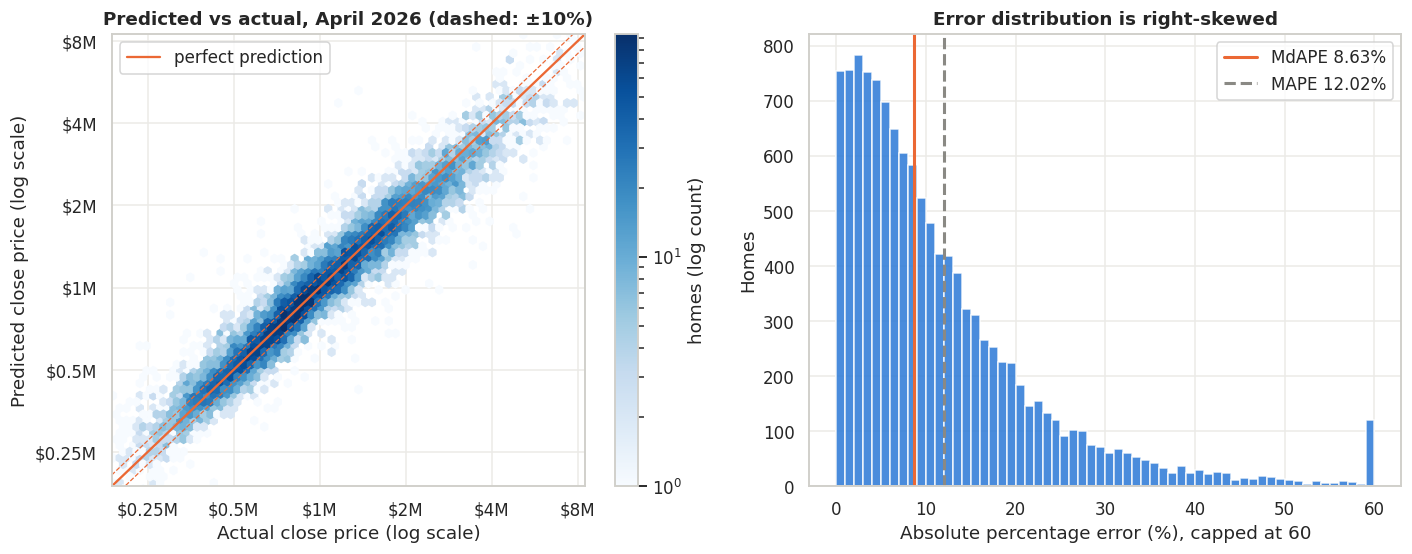

Largest 1% of errors start at 58.8%; the 90th percentile is 25.7%


In [8]:
ape = np.abs(pred_lr - y) / y
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
hb = ax[0].hexbin(y, pred_lr, gridsize=70, xscale="log", yscale="log", mincnt=1, cmap="Blues", bins="log")
lim = [th["price_lo"], th["price_hi"]]
ax[0].plot(lim, lim, color=ORANGE, lw=1.5, label="perfect prediction")
for f in (0.9, 1.1):
    ax[0].plot(lim, [l * f for l in lim], color=ORANGE, lw=0.8, ls="--")
ax[0].set(xlim=lim, ylim=lim, xlabel="Actual close price (log scale)", ylabel="Predicted close price (log scale)",
          title="Predicted vs actual, April 2026 (dashed: ±10%)")
ticks = [250e3, 500e3, 1e6, 2e6, 4e6, 8e6]
for a in (ax[0].xaxis, ax[0].yaxis):
    a.set_major_locator(mtick.FixedLocator(ticks)); a.set_minor_locator(mtick.NullLocator())
    a.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1e6:g}M"))
ax[0].legend(loc="upper left"); fig.colorbar(hb, ax=ax[0], label="homes (log count)")

ax[1].hist(np.clip(ape * 100, 0, 60), bins=60, color=BLUE, alpha=0.85)
ax[1].axvline(np.median(ape) * 100, color=ORANGE, lw=2, label=f"MdAPE {np.median(ape)*100:.2f}%")
ax[1].axvline(ape.mean() * 100, color=GREY, lw=2, ls="--", label=f"MAPE {ape.mean()*100:.2f}%")
ax[1].set(xlabel="Absolute percentage error (%), capped at 60", ylabel="Homes", title="Error distribution is right-skewed")
ax[1].legend()
fig.tight_layout(); save(fig, "predicted_vs_actual"); plt.show()
print(f"Largest 1% of errors start at {np.quantile(ape, 0.99)*100:.1f}%; the 90th percentile is {np.quantile(ape, 0.9)*100:.1f}%")

## 6. Error by price band and by county

Bands are quintiles of the **actual** April 2026 close price. Because a linear model shrinks toward the average, some over-prediction in the cheapest band and under-prediction in the most expensive band is expected (`median_bias` shows the direction).

In [9]:
bands = mdl.price_bands(y, 5)
by_band = mdl.error_by_group(y, pred_lr, bands).rename_axis("price_band")
fmt_table(by_band, GROUP_FMT)

,n,median_price,MdAPE,MAPE,MAE,within_10pct,median_bias
price_band,,,,,,,
Q1: $189K-$575K,"2,461","$450,000",8.33%,12.97%,"$53,936",57.4%,+2.73%
Q2: $575K-$800K,"2,464","$699,000",7.53%,10.49%,"$72,457",62.5%,+0.37%
"Q3: $800K-$1,100K","2,480","$925,000",7.52%,10.39%,"$97,069",61.7%,+0.75%
"Q4: $1,100K-$1,652K","2,335","$1,325,000",8.67%,11.58%,"$156,653",56.0%,-1.63%
"Q5: $1,652K-$8,400K","2,435","$2,300,000",11.78%,14.68%,"$428,100",43.2%,-6.81%


In [10]:
by_county = mdl.error_by_group(y, pred_lr, test.CountyOrParish, min_n=100).sort_values("n", ascending=False).rename_axis("county")
fmt_table(by_county, GROUP_FMT)

,n,median_price,MdAPE,MAPE,MAE,within_10pct,median_bias
county,,,,,,,
Los Angeles,"3,009","$1,011,000",9.42%,12.89%,"$190,669",52.4%,-0.44%
Riverside,"1,875","$639,000",7.66%,11.09%,"$104,551",61.3%,+0.31%
San Diego,"1,421","$1,095,000",8.94%,12.10%,"$190,070",55.5%,-1.97%
San Bernardino,"1,219","$555,000",7.42%,10.64%,"$64,754",62.4%,+0.51%
Orange,"1,165","$1,430,000",7.92%,10.76%,"$202,827",58.8%,-0.91%
Alameda,582,"$1,323,000",10.94%,14.04%,"$211,437",47.1%,-3.62%
Contra Costa,574,"$902,842",7.85%,10.84%,"$141,950",59.6%,-1.99%
Ventura,419,"$999,009",8.89%,11.84%,"$175,525",55.6%,-0.68%
Santa Clara,388,"$1,895,000",8.43%,12.14%,"$264,257",58.8%,-0.30%


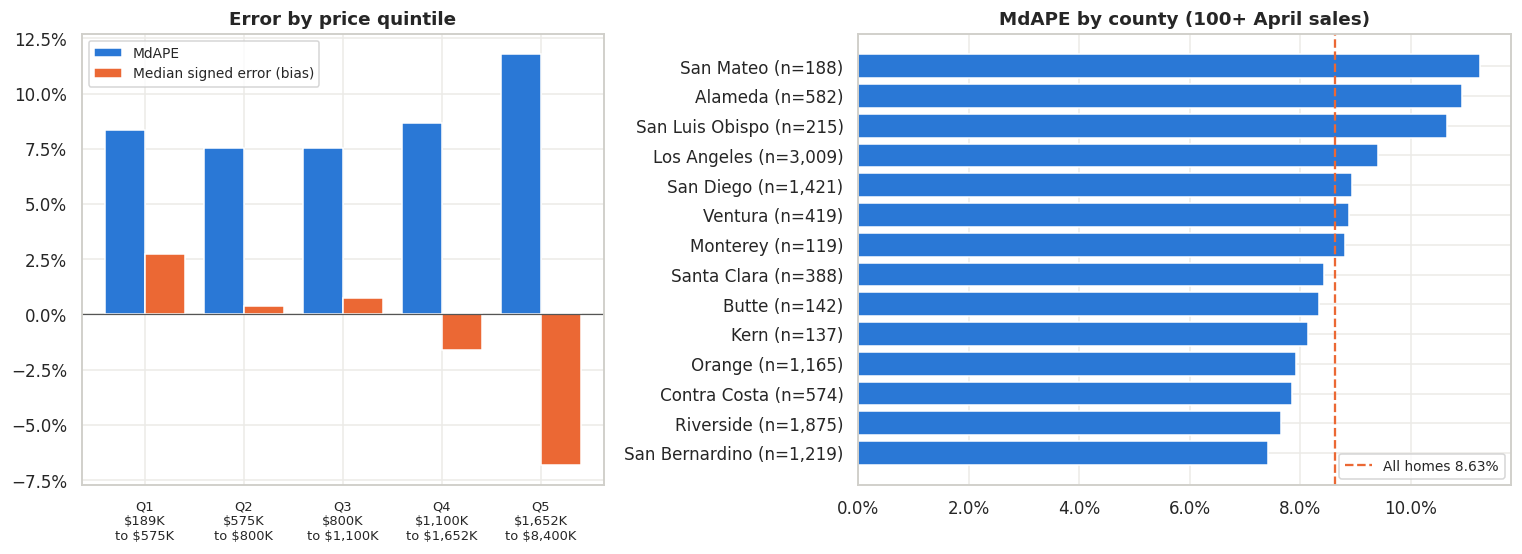

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.25]})
x = np.arange(len(by_band))
ax[0].bar(x - 0.2, by_band.MdAPE, 0.4, color=BLUE, label="MdAPE")
ax[0].bar(x + 0.2, by_band.median_bias, 0.4, color=ORANGE, label="Median signed error (bias)")
ax[0].axhline(0, color="#555", lw=0.8)
ax[0].set_xticks(x, [l.replace(": ", "\n").replace("-", "\nto ").replace("$", r"\$") for l in by_band.index], fontsize=8.5)
ax[0].yaxis.set_major_formatter(mtick.PercentFormatter()); ax[0].legend(fontsize=9)
ax[0].set_title("Error by price quintile")

bc = by_county.sort_values("MdAPE")
ax[1].barh([f"{c} (n={n:,})" for c, n in zip(bc.index, bc.n)], bc.MdAPE, color=BLUE)
ax[1].axvline(b.MdAPE, color=ORANGE, ls="--", lw=1.5, label=f"All homes {b.MdAPE:.2f}%")
ax[1].xaxis.set_major_formatter(mtick.PercentFormatter()); ax[1].legend(fontsize=9, loc="lower right")
ax[1].set_title("MdAPE by county (100+ April sales)")
fig.tight_layout(); save(fig, "error_by_band_and_county"); plt.show()

## 7. What the baseline learned

Coefficients of the standardized numeric and target-encoded inputs, on the log-price scale (a coefficient of 0.10 means about +10.5% price per one standard deviation, holding the other inputs fixed). One-hot county and levels coefficients are not shown: with an intercept they are not uniquely identified, so their individual values are not meaningful. Inputs are strongly correlated (comp price, ZIP, city and latitude all describe location), so these are descriptive, not causal.

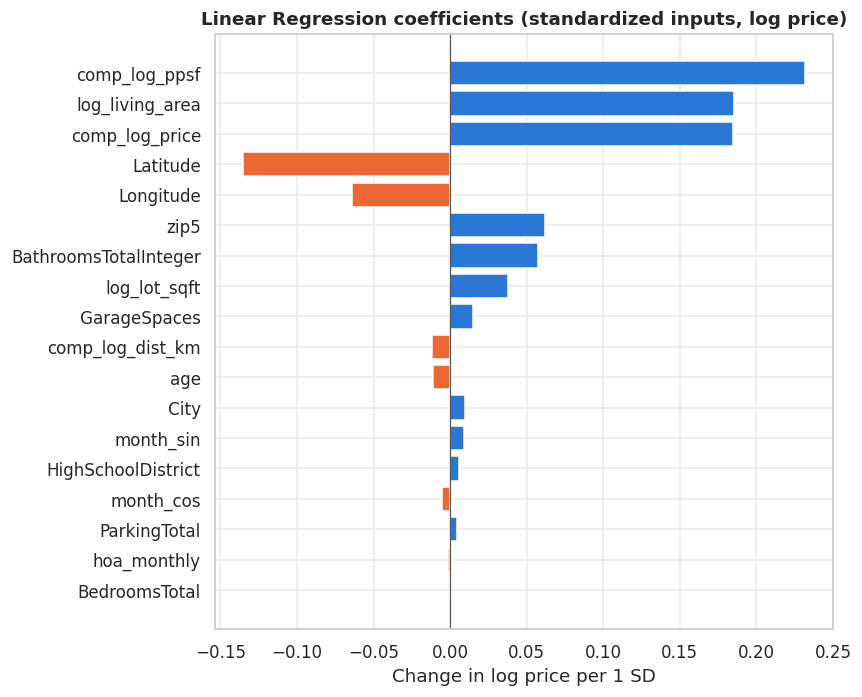

Intercept: 13.868 (exp = $1,054,124)


In [12]:
names = model.named_steps["prep"].get_feature_names_out()
coef = pd.Series(model.named_steps["model"].coef_, index=names)
show = coef[[n.startswith(("num__", "high__")) and "missingindicator" not in n for n in names]]
show.index = show.index.str.replace(r"^(num|high)__", "", regex=True)
show = show.reindex(show.abs().sort_values().index)

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(show.index, show.values, color=[BLUE if v > 0 else ORANGE for v in show.values])
ax.axvline(0, color="#555", lw=0.8)
ax.set(title="Linear Regression coefficients (standardized inputs, log price)", xlabel="Change in log price per 1 SD")
fig.tight_layout(); save(fig, "coefficients"); plt.show()
print(f"Intercept: {model.named_steps['model'].intercept_:.3f} (exp = ${np.exp(model.named_steps['model'].intercept_):,.0f})")

## 8. Stability: rolling-origin backtest

The April score combined with the three validation months from section 3 gives four consecutive cutoffs, each with its own 15-month window, thresholds and preprocessor. The April row is recomputed by the same function and must match section 4 exactly.

In [13]:
apr_table, _ = mdl.rolling_backtest(clean, baseline, [TEST_MONTH], X_MONTHS)
assert np.isclose(apr_table.MdAPE.iloc[0], b.MdAPE) and apr_table.n.iloc[0] == b.n, "backtest does not reproduce the test score"
backtest = pd.concat([val_table.assign(role="validation"), apr_table.assign(role="test")], ignore_index=True)
show_metrics(backtest[["test_month", "role", "train_months", "n_train", "n", "MdAPE", "R2", "MAPE", "MAE", "within_10pct", "median_bias_pct"]])

,test_month,role,train_months,n_train,n,MdAPE,R2,MAPE,MAE,within_10pct,median_bias_pct
0,2026-01,validation,2024-10 to 2025-12,"160,843","7,333",8.91%,0.8808,12.59%,"$154,095",54.7%,+1.31%
1,2026-02,validation,2024-11 to 2026-01,"156,092","8,744",8.80%,0.8837,12.25%,"$159,512",55.1%,+0.32%
2,2026-03,validation,2024-12 to 2026-02,"154,330","11,284",8.52%,0.8807,11.90%,"$156,158",56.5%,-0.16%
3,2026-04,test,2025-01 to 2026-03,"155,216","12,175",8.63%,0.8886,12.02%,"$161,003",56.2%,-0.61%


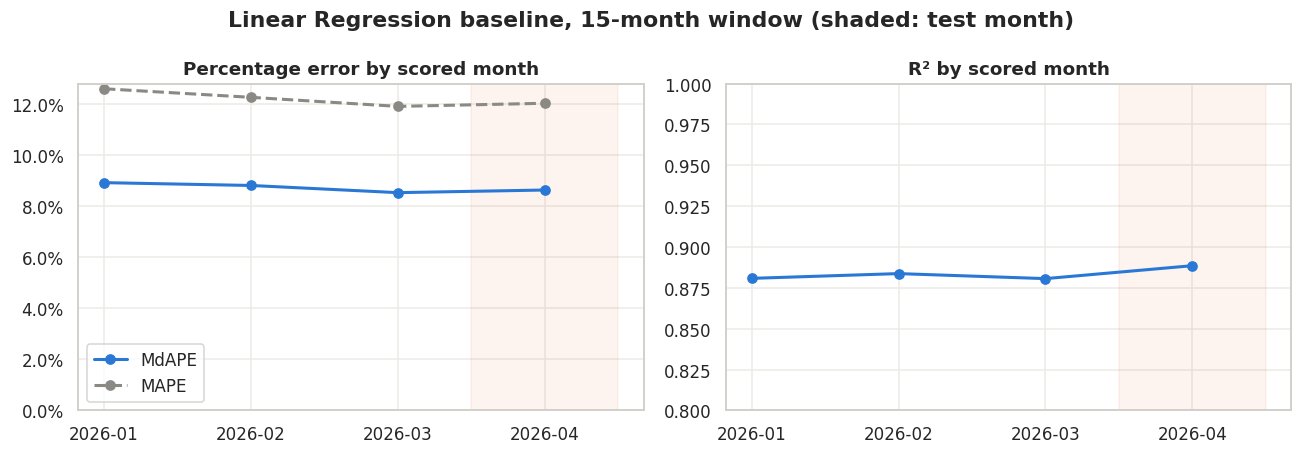

MdAPE across 4 cutoffs: 8.52% - 8.91% (spread 0.39 points); R2 0.8807 - 0.8886


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(backtest.test_month, backtest.MdAPE, marker="o", color=BLUE, lw=2, label="MdAPE")
ax[0].plot(backtest.test_month, backtest.MAPE, marker="o", color=GREY, lw=2, ls="--", label="MAPE")
ax[0].yaxis.set_major_formatter(mtick.PercentFormatter()); ax[0].set_ylim(0, None); ax[0].legend()
ax[0].set_title("Percentage error by scored month")
ax[1].plot(backtest.test_month, backtest.R2, marker="o", color=BLUE, lw=2)
ax[1].set_ylim(0.8, 1.0); ax[1].set_title("R² by scored month")
for a in ax: a.axvspan(2.5, 3.5, color=ORANGE, alpha=0.08)
fig.suptitle("Linear Regression baseline, 15-month window (shaded: test month)", fontweight="bold")
fig.tight_layout(); save(fig, "backtest_stability"); plt.show()
spread = backtest.MdAPE.max() - backtest.MdAPE.min()
print(f"MdAPE across 4 cutoffs: {backtest.MdAPE.min():.2f}% - {backtest.MdAPE.max():.2f}% (spread {spread:.2f} points); "
      f"R2 {backtest.R2.min():.4f} - {backtest.R2.max():.4f}")

## 9. Predicting the close price of one property

Task step 6: use the trained model to output a predicted close price. The fitted pipeline takes a one-row table with the 24 input features (unscaled, missing values allowed) and returns a dollar figure. Three April 2026 sales are shown: one near the median error and the best and worst of a random sample. The Week 9 app will build the same input row for any typed-in address, computing its comp features from the latest sales.

In [15]:
def predict_one(fitted, row: pd.DataFrame) -> float:
    pp.assert_no_leakage()
    return float(mdl.predict_price(fitted, row)[0])

sample = test.assign(pred=pred_lr, ape=ape * 100).sample(500, random_state=pp.SEED)
picks = pd.concat([sample.iloc[[(sample.ape - np.median(ape) * 100).abs().argmin()]],
                   sample.nsmallest(1, "ape"), sample.nlargest(1, "ape")])
for _, r in picks.iterrows():
    p = predict_one(model, r.to_frame().T.astype(test.dtypes.to_dict()))
    print(f"{r.City}, {r.CountyOrParish} ({r.zip5}) | {np.exp(r.log_living_area):,.0f} sq ft, "
          f"{r.BedroomsTotal:.0f} bd / {r.BathroomsTotalInteger:.0f} ba, age {r.age:.0f}")
    print(f"   predicted ${p:,.0f}   actual ${r.ClosePrice:,.0f}   error {(p - r.ClosePrice) / r.ClosePrice * 100:+.1f}%")

Beaumont, Riverside (92223) | 1,868 sq ft, 3 bd / 3 ba, age 8
   predicted $511,652   actual $560,000   error -8.6%
Mission Viejo, Orange (92692) | 3,520 sq ft, 5 bd / 3 ba, age 37
   predicted $1,959,077   actual $1,959,000   error +0.0%
Sun Valley, Los Angeles (91352) | 2,537 sq ft, 7 bd / 6 ba, age 72
   predicted $1,314,031   actual $400,000   error +228.5%


## 10. Save the baseline and its results

- `models/baseline_linear_regression.joblib`: the fitted pipeline (preprocessor + Linear Regression).
- `results/model_results.csv`: the comparison table that Week 5 appends to (one row per model, April 2026 test metrics).
- `results/baseline_backtest.csv`, `results/baseline_error_by_price_band.csv`, `results/baseline_error_by_county.csv`.
- `results/baseline_test_predictions.csv`: every April 2026 prediction with its error (no banned fields).

In [16]:
joblib.dump(model, MODEL_DIR / "baseline_linear_regression.joblib")

leader = results.reset_index().assign(test_month=TEST_MONTH, train_window_months=X_MONTHS,
                                      train_rows=len(train), validation_MdAPE_mean=np.nan)
leader.loc[leader.model == "Baseline: Linear Regression", "validation_MdAPE_mean"] = val_table.MdAPE.mean()
leader.to_csv(RES_DIR / "model_results.csv", index=False)
backtest.to_csv(RES_DIR / "baseline_backtest.csv", index=False)
by_band.reset_index().to_csv(RES_DIR / "baseline_error_by_price_band.csv", index=False)
by_county.reset_index().to_csv(RES_DIR / "baseline_error_by_county.csv", index=False)
out = test[["ListingKey", "close_month", "City", "CountyOrParish", "zip5", "ClosePrice"]].assign(
    predicted_price=pred_lr.round(0), pct_error=((pred_lr - y) / y * 100).round(3), price_band=bands.values)
assert not set(out.columns) & set(pp.LEAKAGE_FIELDS)
out.to_csv(RES_DIR / "baseline_test_predictions.csv", index=False)

run_info = {"model": "LinearRegression (scikit-learn defaults)", "target": "log(ClosePrice)", "test_month": TEST_MONTH,
            "train_window_months": X_MONTHS, "train_rows": len(train), "test_rows": len(test), "seed": pp.SEED,
            "test_metrics": {k: float(v) for k, v in b.items()},
            "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                         "scikit-learn": sklearn.__version__}}
(RES_DIR / "baseline_run_info.json").write_text(json.dumps(run_info, indent=2))
for f in sorted(list(RES_DIR.iterdir()) + list(MODEL_DIR.iterdir())): print(f"{f.relative_to(ROOT)!s:48s} {f.stat().st_size/1e3:9.1f} KB")

models/baseline_linear_regression.joblib              65.2 KB
results/baseline_backtest.csv                          1.1 KB
results/baseline_error_by_county.csv                   1.7 KB
results/baseline_error_by_price_band.csv               0.7 KB
results/baseline_run_info.json                         0.7 KB
results/baseline_test_predictions.csv               1108.6 KB
results/model_results.csv                              1.0 KB


## 11. Summary and hand-off to Week 5

**Baseline result (April 2026 test month, 12,175 sales, scored once):**

| Metric | Linear Regression baseline |
|---|---|
| **MdAPE (headline)** | **8.63%** |
| R² (dollars) | **0.8886** (0.9322 on log price) |
| MAPE | 12.02% |
| MAE / RMSE | $161,003 / $319,549 (median absolute error $76,128) |
| Within 5% / 10% / 20% of sale price | 31.1% / 56.2% / 83.4% |
| Median signed error (bias) | −0.61% |

**It clearly beats the no-model reference points.** Predicting the median price of the 10 nearest earlier sales gives MdAPE 12.03% (R² 0.7066); comp price per sq ft × living area gives 12.71% (R² 0.8606). The baseline cuts the typical error by about 3.4 points (roughly 28% lower).

**Validation agrees, and the April score is not a lucky month.** On January, February and March 2026 (scored before April was touched) the same pipeline gives MdAPE 8.91%, 8.80% and 8.52% (mean 8.75%, identical to the Week 3 Linear Regression result at X = 15) and R² 0.881–0.884. Across all four cutoffs MdAPE stays within 8.52–8.91% (a spread of 0.39 points). That spread is a useful noise yardstick: a Week 5 model should beat the baseline by clearly more than 0.4 points, on every cutoff, before we call it better.

**Where the baseline struggles.**
- **Expensive homes:** the top price quintile ($1.65M+) has MdAPE 11.78% and is under-predicted (median bias −6.81%); the cheapest quintile is over-predicted (+2.73%). The middle three bands sit at 7.5–8.7%. This is the shrink-toward-the-average pattern expected from a linear model.
- **Counties:** San Mateo (11.26%), Alameda (10.94%) and San Luis Obispo (10.67%) are the weakest; San Bernardino (7.42%) and Riverside (7.66%) the strongest. Los Angeles, the largest county (3,009 sales), is 9.42%.
- **Tail:** errors are right-skewed (MAPE 12.02% vs MdAPE 8.63%). 10% of homes are off by more than 25.7%, and 1% by more than 58.8%. The worst example in section 9 is a $400,000 Sun Valley sale of a 7-bed, 2,537 sq ft home predicted at $1.31M. A record like that may be a non-market or distressed sale, which no property-characteristics model can see; this is why MdAPE is the headline metric.

**What drives the predictions.** Comp price per sq ft, living area and comp median price have by far the largest coefficients, followed by latitude/longitude and the ZIP encoding. Bedrooms add almost nothing once living area is known. Inputs are correlated, so these are descriptive, not causal.

**Conversion back to dollars.** A smearing correction (factor 1.0135, learned on train) leaves MdAPE unchanged at 8.63% and only moves MAPE/MAE slightly, so the plain `exp()` is kept.

**Recorded results.** `results/model_results.csv` (side-by-side table Week 5 appends to), `results/baseline_backtest.csv`, error by price band and county, all April predictions, `results/baseline_run_info.json` (metrics, seed, versions) and the fitted pipeline in `models/baseline_linear_regression.joblib`.

**Hand-off to Week 5 (Decision Tree and Random Forest).** Build each model with `mdl.make_pipeline(model)` on the same `train.csv` / `test.csv`, score it with `mdl.full_metrics`, and append a row to `results/model_results.csv` so all models sit in one table. Choose hyperparameters with `mdl.rolling_backtest` on the January–March 2026 validation months, never on April. **Numbers to beat: April MdAPE 8.63% / R² 0.889, validation MdAPE mean 8.75%.** Week 3's quick HistGradientBoosting check (validation MdAPE 7.41%) suggests tree models should pick up the non-linear location and luxury effects the linear model misses. Known baseline limitations: no interactions (for example size × location) because the model is linear in log price; one-hot county and levels coefficients are not individually identifiable; high-school district is still unknown for 33% of rows (Week 6).